In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

df = pd.read_csv("creditcard.csv")

print("Dataset Shape:", df.shape)
print(df["Class"].value_counts())

Dataset Shape: (284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [2]:
X = df.drop("Class", axis=1)
y = df["Class"]

X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_normal = X_train_all[y_train_all == 0]
X_train, X_val = train_test_split(
    X_normal, test_size=0.1, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Normal training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Normal training data: (204705, 30)
Validation data: (22746, 30)
Testing data: (56962, 30)


In [3]:
model = models.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(14, activation="relu"),
    layers.Dense(7, activation="relu"),
    layers.Dense(4, activation="relu"),
    layers.Dense(7, activation="relu"),
    layers.Dense(14, activation="relu"),
    layers.Dense(30, activation="linear")
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           434 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │            35 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 30)             │           450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,168 (4.56 KB)

 Trainable params: 1,168 (4.56 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(X_val, X_val)
)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8702 - mae: 0.6244 - val_loss: 0.7520 - val_mae: 0.5850
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.7401 - mae: 0.5748 - val_loss: 0.6957 - val_mae: 0.5653
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6975 - mae: 0.5591 - val_loss: 0.6623 - val_mae: 0.5524
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6660 - mae: 0.5487 - val_loss: 0.6375 - val_mae: 0.5443
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6421 - mae: 0.5410 - val_loss: 0.6208 - val_mae: 0.5380
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6286 - mae: 0.5365 - val_loss: 0.6107 - val_mae: 0.5356
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6177 - mae: 0.5330 - val_loss: 0.6013 - val_mae: 0.5313
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6088 - mae: 0.5289 - val_loss: 0.5930 - val_mae: 0.5273
Epoch 9/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - lo

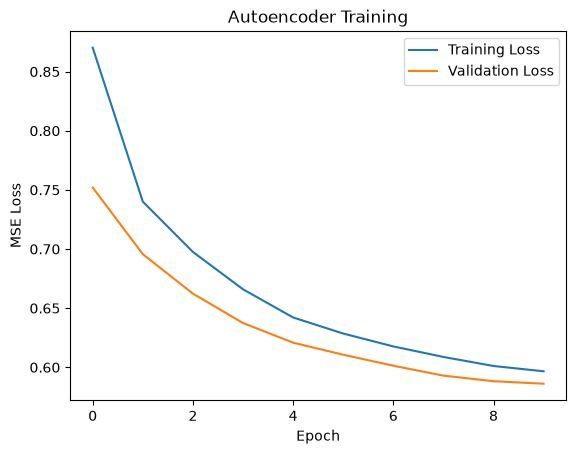

In [5]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training")
plt.legend()
plt.show()

In [6]:
val_reconstructed = model.predict(X_val, verbose=0)

val_error = np.mean(
    np.square(X_val - val_reconstructed), axis=1
)

threshold = np.percentile(val_error, 99.5)
print("Anomaly Threshold:", threshold)

Anomaly Threshold: 4.863515758722418


In [7]:
test_reconstructed = model.predict(X_test, verbose=0)

test_error = np.mean(
    np.square(X_test - test_reconstructed), axis=1
)

y_pred = (test_error > threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, test_error), 4))

Confusion Matrix:
[[56534   330]
 [   26    72]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00     56864
       Fraud       0.18      0.73      0.29        98

    accuracy                           0.99     56962
   macro avg       0.59      0.86      0.64     56962
weighted avg       1.00      0.99      1.00     56962

ROC-AUC: 0.9478


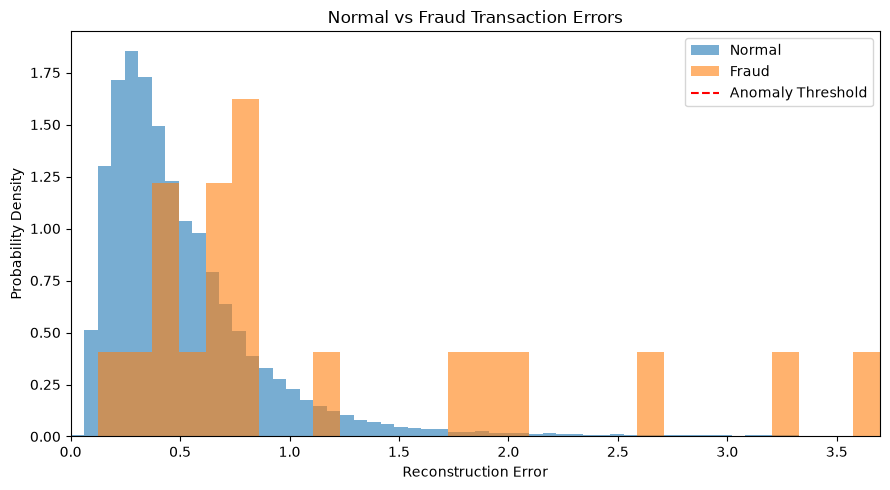

In [9]:
normal_error = test_error[y_test.to_numpy() == 0]
fraud_error = test_error[y_test.to_numpy() == 1]

x_limit = np.percentile(test_error, 99)

plt.figure(figsize=(9, 5))
plt.hist(normal_error, bins=60, range=(0, x_limit),
         density=True, alpha=0.6, label="Normal")
plt.hist(fraud_error, bins=30, range=(0, x_limit),
         density=True, alpha=0.6, label="Fraud")
plt.axvline(threshold, color="red", linestyle="--",
            label="Anomaly Threshold")
plt.xlim(0, x_limit)
plt.xlabel("Reconstruction Error")
plt.ylabel("Probability Density")
plt.title("Normal vs Fraud Transaction Errors")
plt.legend()
plt.tight_layout()
plt.show()